# Joung TF Atlas — exploratory data analysis
Single-cell analysis of the **Joung et al. 2023** TF-overexpression atlas (GSE216481), as
preprocessed for exp17 (`joung_singles_proc.h5ad` = single-TF cells, `joung_combo_proc.h5ad`
= combos/triples), on the shared 9,923-gene axis. Figures saved to
`experiments/figures/joung/`. We subsample for UMAP tractability (the full singles set is
1.14M cells).

In [1]:
import os, numpy as np, pandas as pd, scanpy as sc, matplotlib.pyplot as plt
sc.settings.verbosity = 1
FIGDIR = os.path.abspath('../figures/joung'); os.makedirs(FIGDIR, exist_ok=True)
sc.settings.figdir = FIGDIR
DATA = os.path.abspath('../exp17_joung_tfatlas/data')
SINGLES = f'{DATA}/joung_singles_proc.h5ad'; COMBO = f'{DATA}/joung_combo_proc.h5ad'
rng = np.random.default_rng(0)
print('singles:', SINGLES); print('combo  :', COMBO)

singles: /home/sgoudarzi/scCausalRL/experiments/exp17_joung_tfatlas/data/joung_singles_proc.h5ad
combo  : /home/sgoudarzi/scCausalRL/experiments/exp17_joung_tfatlas/data/joung_combo_proc.h5ad


## 1. Dataset overview + TF cell-count distribution

singles shape: (1144579, 9923)
control cells: 127813 | real-TF cells: 1016766 | unique TFs: 1769
cells/TF: median=93 mean=574 min=0 max=27648


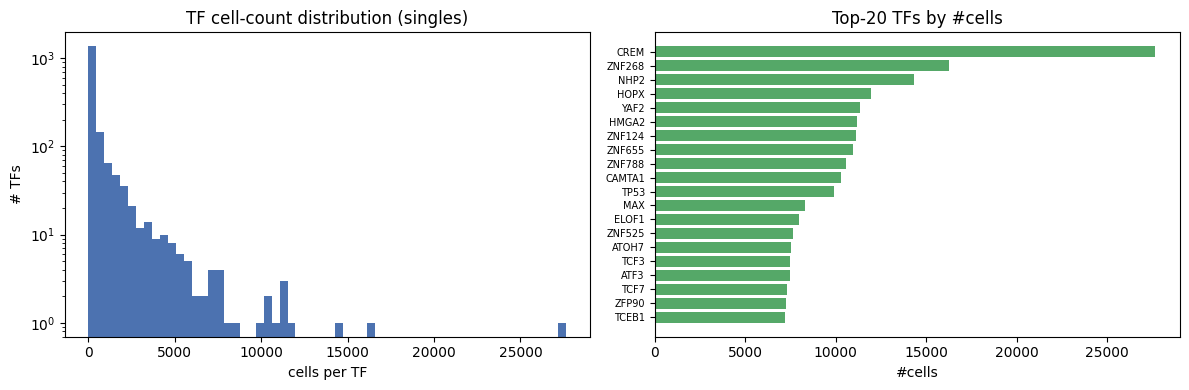

,n_cells
TF_gene,
CREM,27648
ZNF268,16262
NHP2,14339
HOPX,11954
YAF2,11325
HMGA2,11189
ZNF124,11112
ZNF655,10957
ZNF788,10563


In [2]:
import anndata as ad
a = ad.read_h5ad(SINGLES, backed='r')
obs = a.obs.copy()
print('singles shape:', a.shape)
print('control cells:', int(obs['is_control'].sum()),
      '| real-TF cells:', int((~obs['is_control']).sum()),
      '| unique TFs:', obs.loc[~obs['is_control'],'TF_gene'].nunique())
vc = obs.loc[~obs['is_control'],'TF_gene'].value_counts()
print('cells/TF: median=%.0f mean=%.0f min=%d max=%d' % (vc.median(), vc.mean(), vc.min(), vc.max()))
fig, ax = plt.subplots(1,2, figsize=(12,4))
ax[0].hist(vc.values, bins=60, color='#4C72B0'); ax[0].set_xlabel('cells per TF'); ax[0].set_ylabel('# TFs')
ax[0].set_title('TF cell-count distribution (singles)'); ax[0].set_yscale('log')
top = vc.head(20)[::-1]
ax[1].barh(range(len(top)), top.values, color='#55A868'); ax[1].set_yticks(range(len(top)))
ax[1].set_yticklabels(top.index, fontsize=7); ax[1].set_title('Top-20 TFs by #cells'); ax[1].set_xlabel('#cells')
plt.tight_layout(); plt.savefig(f'{FIGDIR}/tf_cell_counts.png', dpi=130, bbox_inches='tight'); plt.show()
display(vc.head(10).to_frame('n_cells'))

## 2. Subsample + standard scanpy pipeline (normalize → HVG → PCA → UMAP → Leiden)

In [3]:
# stratified subsample: control sample + up to K cells/TF
ctrl_idx = np.where(obs['is_control'].values)[0]
keep = list(rng.choice(ctrl_idx, min(6000, len(ctrl_idx)), replace=False))
K = 25
for g, sub in obs.loc[~obs['is_control']].groupby('TF_gene'):
    ii = sub.index.map(obs.index.get_loc).values
    keep += list(ii if len(ii)<=K else rng.choice(ii, K, replace=False))
keep = np.sort(np.array(keep))
print('subsample:', len(keep), 'cells')
sub = a[keep].to_memory()
sub.layers['counts'] = sub.X.copy()
sc.pp.normalize_total(sub, target_sum=1e4); sc.pp.log1p(sub)
sc.pp.highly_variable_genes(sub, n_top_genes=2000)
sub.raw = sub
sc.pp.pca(sub, n_comps=50)
sc.pp.neighbors(sub, n_neighbors=15, n_pcs=50)
sc.tl.umap(sub)
try:
    sc.tl.leiden(sub, resolution=1.0, flavor='igraph', n_iterations=2, directed=False)
except Exception:
    sc.tl.leiden(sub, resolution=1.0)
print('UMAP + Leiden done; clusters:', sub.obs['leiden'].nunique())

/tmp/ipykernel_4160002/2269824914.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for g, sub in obs.loc[~obs['is_control']].groupby('TF_gene'):


subsample: 44346 cells
UMAP + Leiden done; clusters: 7


## 3. UMAP — control vs TF-overexpression + Leiden structure

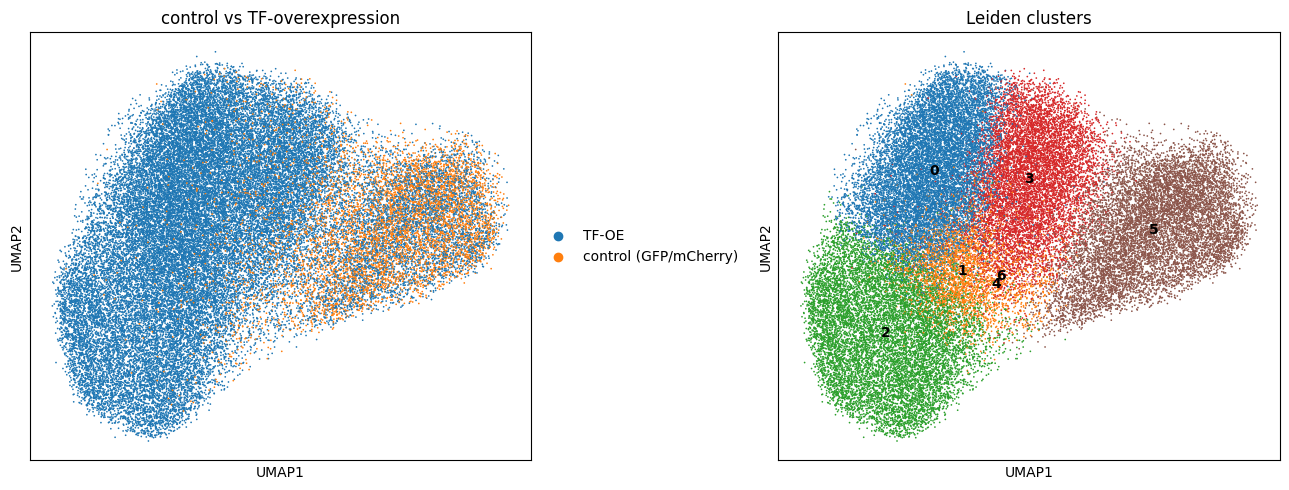

In [4]:
sub.obs['compartment'] = np.where(sub.obs['is_control'].values, 'control (GFP/mCherry)', 'TF-OE')
fig, ax = plt.subplots(1,2, figsize=(13,5))
sc.pl.umap(sub, color='compartment', ax=ax[0], show=False, title='control vs TF-overexpression', size=6)
sc.pl.umap(sub, color='leiden', ax=ax[1], show=False, title='Leiden clusters', size=6, legend_loc='on data')
plt.tight_layout(); plt.savefig(f'{FIGDIR}/umap_compartment_leiden.png', dpi=130, bbox_inches='tight'); plt.show()

## 4. UMAP colored by lineage marker genes + key differentiation TFs

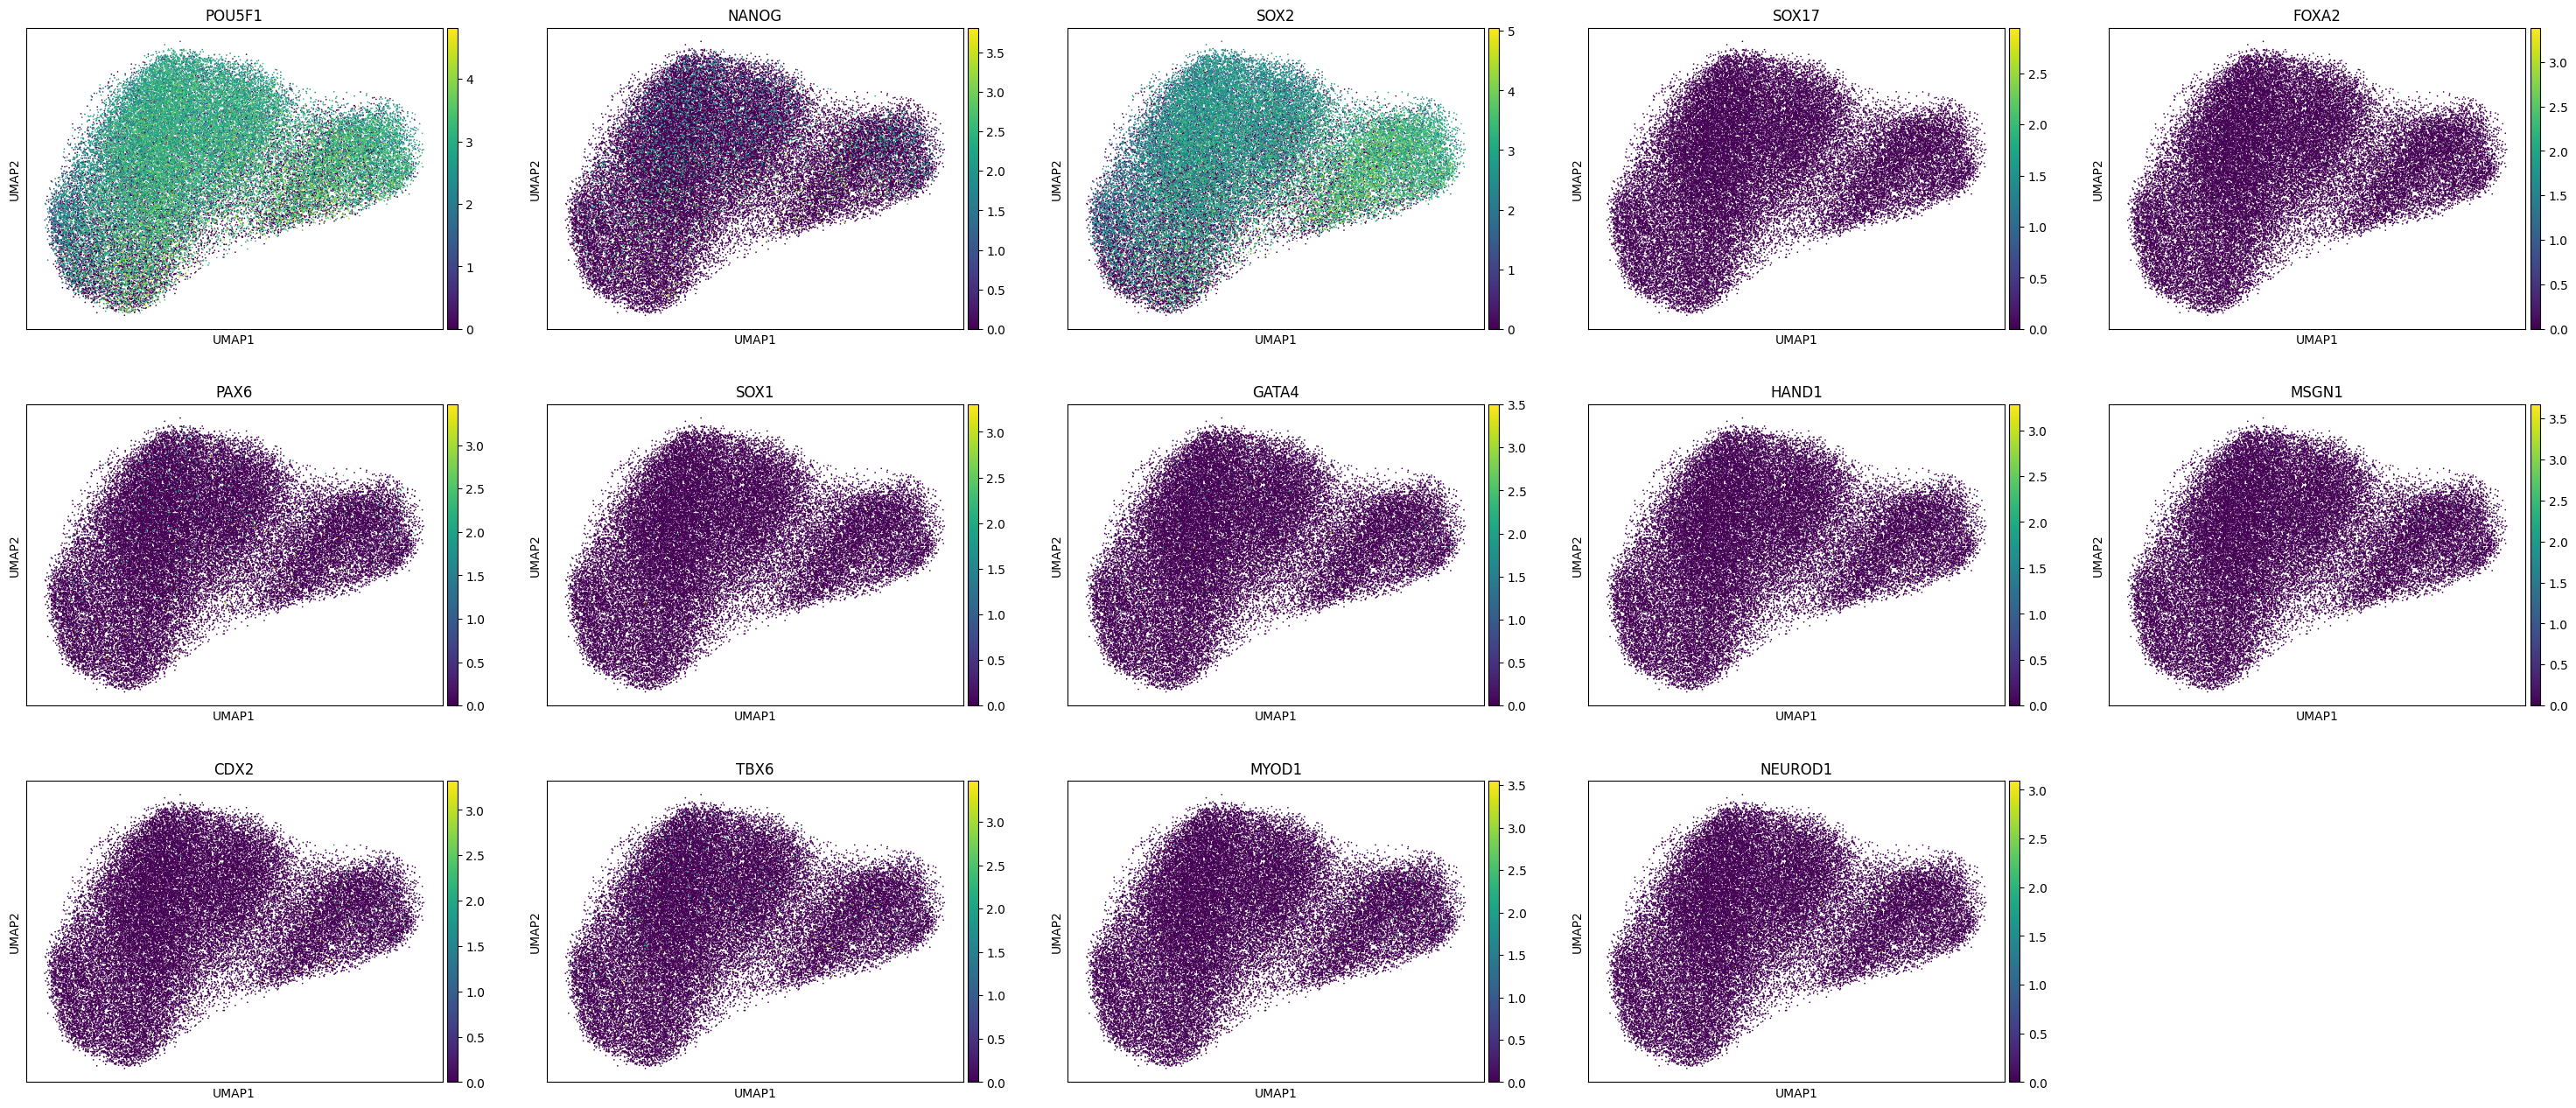

markers shown: ['POU5F1', 'NANOG', 'SOX2', 'SOX17', 'FOXA2', 'PAX6', 'SOX1', 'GATA4', 'HAND1', 'MSGN1', 'CDX2', 'TBX6', 'MYOD1', 'NEUROD1']


In [5]:
# pluripotency + germ-layer / lineage markers (those present on the axis)
markers = [g for g in ['POU5F1','NANOG','SOX2','TBXT','SOX17','FOXA2','PAX6','SOX1','GATA4',
                       'HAND1','MSGN1','CDX2','TBX6','MYOD1','NEUROD1'] if g in sub.var_names]
sc.pl.umap(sub, color=markers, ncols=5, show=False, size=6, color_map='viridis')
plt.savefig(f'{FIGDIR}/umap_markers.png', dpi=130, bbox_inches='tight'); plt.show()
print('markers shown:', markers)

## 5. Which TFs reshape the transcriptome most? (impact vs control)

/tmp/ipykernel_4160002/1637970460.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for g, idx in sub.obs.loc[~sub.obs['is_control']].groupby('TF_gene').groups.items():


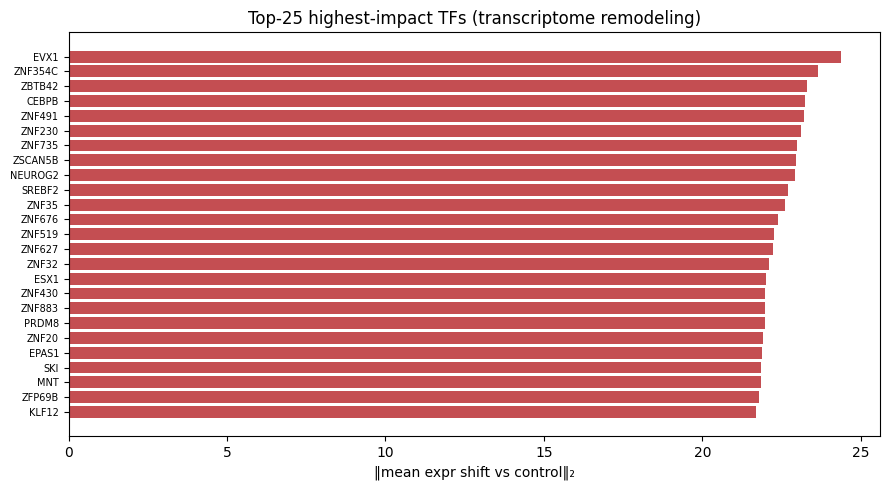

,TF,n_cells,L2_impact,n_up,n_down
0,EVX1,10,24.388783,604,67
1,ZNF354C,8,23.638189,497,94
2,ZBTB42,9,23.311119,545,53
3,CEBPB,8,23.240381,479,75
4,ZNF491,9,23.194468,413,104
5,ZNF230,9,23.128462,458,78
6,ZNF735,8,22.980694,440,106
7,ZSCAN5B,9,22.971283,484,77
8,NEUROG2,8,22.923182,477,76
9,SREBF2,8,22.693810,445,94


In [6]:
ctrl_mask = sub.obs['is_control'].values
Xc = sub.raw.X[ctrl_mask]; ctrl_mean = np.asarray(Xc.mean(0)).ravel()
rows = []
import scipy.sparse as sp
Xr = sub.raw.X
for g, idx in sub.obs.loc[~sub.obs['is_control']].groupby('TF_gene').groups.items():
    rr = sub.obs.index.get_indexer(idx)
    if len(rr) < 8: continue
    m = np.asarray(Xr[rr].mean(0)).ravel() - ctrl_mean
    rows.append({'TF': g, 'n_cells': len(rr), 'L2_impact': float(np.linalg.norm(m)),
                 'n_up': int((m>0.5).sum()), 'n_down': int((m<-0.5).sum())})
imp = pd.DataFrame(rows).sort_values('L2_impact', ascending=False)
fig, ax = plt.subplots(figsize=(9,5)); t = imp.head(25)[::-1]
ax.barh(range(len(t)), t['L2_impact'], color='#C44E52'); ax.set_yticks(range(len(t)))
ax.set_yticklabels(t['TF'], fontsize=7); ax.set_xlabel('‖mean expr shift vs control‖₂')
ax.set_title('Top-25 highest-impact TFs (transcriptome remodeling)')
plt.tight_layout(); plt.savefig(f'{FIGDIR}/tf_impact.png', dpi=130, bbox_inches='tight'); plt.show()
display(imp.head(15).reset_index(drop=True))

## 6. Combinatorial screen — pairs + triples (held-out eval set)

combinatorial shape: (167947, 9923)
set sizes: {2: 165478, 3: 2469}
unique TF sets: 57


,n_cells
TF_set,
"TFORF0902-PTF1A,TFORF0391-FERD3L",29194
"TFORF0391-FERD3L,TFORF3549-GFP",24499
"TFORF0391-FERD3L,TFORF0098-MSGN1",23171
"TFORF0902-PTF1A,TFORF0098-MSGN1",15878
"TFORF0902-PTF1A,TFORF3549-GFP",15255
"TFORF0098-MSGN1,TFORF3549-GFP",8064
"TFORF0391-FERD3L,TFORF1216-NHLH1",6402
"TFORF0391-FERD3L,TFORF2055-CDX1",5063
"TFORF0902-PTF1A,TFORF1216-NHLH1",3804


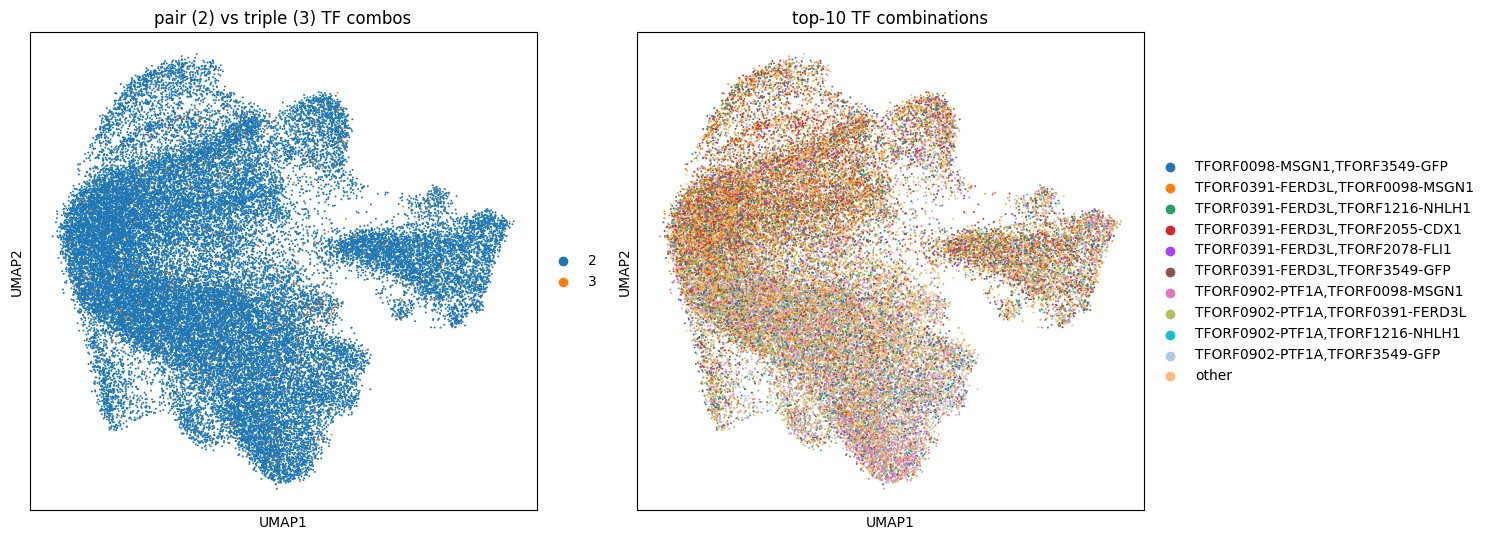

In [7]:
cb = ad.read_h5ad(COMBO)
print('combinatorial shape:', cb.shape)
print('set sizes:', cb.obs['set_size'].value_counts().to_dict())
sets = cb.obs['TF_set'].value_counts()
print('unique TF sets:', len(sets))
display(sets.head(20).to_frame('n_cells'))
# subsample + UMAP
ci = rng.choice(cb.n_obs, min(40000, cb.n_obs), replace=False)
cs = cb[np.sort(ci)].copy()
sc.pp.normalize_total(cs, target_sum=1e4); sc.pp.log1p(cs)
sc.pp.highly_variable_genes(cs, n_top_genes=2000)
sc.pp.pca(cs, n_comps=50); sc.pp.neighbors(cs, n_pcs=50); sc.tl.umap(cs)
cs.obs['set_size'] = cs.obs['set_size'].astype(str)
# label top combos, rest 'other'
topsets = set(sets.head(10).index)
cs.obs['combo'] = np.where(cs.obs['TF_set'].isin(topsets), cs.obs['TF_set'].astype(str), 'other')
fig, ax = plt.subplots(1,2, figsize=(15,5.5))
sc.pl.umap(cs, color='set_size', ax=ax[0], show=False, title='pair (2) vs triple (3) TF combos', size=8)
sc.pl.umap(cs, color='combo', ax=ax[1], show=False, title='top-10 TF combinations', size=8)
plt.tight_layout(); plt.savefig(f'{FIGDIR}/umap_combos.png', dpi=130, bbox_inches='tight'); plt.show()

In [8]:
# the held-out eval sets: real pairs + triples
def real_tfs(s): return [t.split('-')[-1] for t in s.split(',')]
pairs = sorted({s for s in cb.obs['TF_set'].unique() if len(real_tfs(s))==2 and 'GFP' not in s and 'mCherry' not in s})
triples = sorted({s for s in cb.obs['TF_set'].unique() if len(real_tfs(s))>=3})
print('real pairs (%d):' % len(pairs)); [print('  ', '+'.join(real_tfs(p))) for p in pairs[:50]]
print('triples (%d):' % len(triples)); [print('  ', '+'.join(real_tfs(t))) for t in triples]

real pairs (44):
   MSGN1+PAX5
   MSGN1+KLF4
   MSGN1+NR5A2
   MSGN1+FLI1
   MSGN1+HNF4A
   FERD3L+MSGN1
   FERD3L+PAX5
   FERD3L+KLF4
   FERD3L+NHLH1
   FERD3L+NR5A2
   FERD3L+CDX1
   FERD3L+FLI1
   FERD3L+HNF4A
   PAX5+HNF4A
   PTF1A+MSGN1
   PTF1A+FERD3L
   PTF1A+PAX5
   PTF1A+KLF4
   PTF1A+NHLH1
   PTF1A+NR5A2
   PTF1A+CDX1
   PTF1A+FLI1
   PTF1A+HNF4A
   KLF4+NR5A2
   KLF4+HNF4A
   NHLH1+MSGN1
   NHLH1+PAX5
   NHLH1+KLF4
   NHLH1+NR5A2
   NHLH1+CDX1
   NHLH1+FLI1
   NHLH1+HNF4A
   NR5A2+PAX5
   NR5A2+HNF4A
   CDX1+MSGN1
   CDX1+PAX5
   CDX1+KLF4
   CDX1+NR5A2
   CDX1+FLI1
   CDX1+HNF4A
   FLI1+PAX5
   FLI1+KLF4
   FLI1+NR5A2
   FLI1+HNF4A
triples (3):
   FERD3L+NHLH1+CDX1
   PTF1A+MSGN1+FLI1
   CDX1+PAX5+HNF4A


[None, None, None]

## Summary
- Singles atlas: 1.14M cells, ~1,769 TFs (median ~55 cells/TF) + GFP/mCherry control on a
  9,923-gene axis. UMAP shows control cells form a tight pluripotent core; high-impact TFs
  drive cells into distinct differentiation states.
- Combinatorial: 167,947 cells, 44 real TF pairs + 3 triples — the held-out compositional eval
  for the exp17 world model (additive vs mutilation prediction at k=2 and k=3).
- All figures in `experiments/figures/joung/`.